# Track 01 Workflow: How Much of the Preeclampsia Signal Is Just Delivery Timing?

This notebook follows the [analysis workflow](../3-workflow.md). Sections 1 to 8 are the guided steps, with our decisions filled in wherever the template said **You decide**. Sections 9 to 13 add the analyses that answer our question.

Run it with **Restart & Run All**. It takes about 10 minutes on a laptop, mostly in Section 10. All figures and tables are saved to `results/`.

> **How this fits the submission.** This is the team's core notebook, following the official workflow. It compares preeclampsia with the 5 spontaneous preterm births without covariates. The companion notebook [`track01_analysis.ipynb`](track01_analysis.ipynb) adds models adjusted for growth restriction and fetal sex, and answers question 9 with the single-cell data. Growth restriction occurs only in the preeclampsia group here, so Section 13 checks how much it matters.

## 0. Setup

For local runs, install the pinned packages from `../requirements.txt`. Once this branch is published, the first code cell can clone it in Google Colab and pin the same dependencies.


In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/track-01").exists():
        subprocess.run(["git", "clone", "-q", "--branch", "integrate-track01-analysis",
                        "https://github.com/sanjnabandaru/track-01.git", "/content/track-01"], check=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "numpy==2.4.6", "pandas==2.3.3", "matplotlib==3.11.2",
        "scikit-learn==1.9.1", "scipy==1.17.1", "statsmodels==0.15.0",
        "pydeseq2==0.5.4",
    ], check=True)
    os.chdir("/content/track-01/notebooks")

# PyDESeq2 prints harmless overflow warnings for a few genes with extreme counts. It runs its fits in
# separate worker processes, so we silence warnings through the environment (which workers inherit) as well.
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Works from track-01/notebooks or from a submission folder (submissions/<team>/notebooks)
DATA_DIR = next((p for p in [Path("../data"), Path("../../../track-01/data")] if p.exists()), Path("../data"))
RESULTS_DIR = Path("results") / "workflow"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(2026)   # only used for jitter and the random draws in Section 10

# The same color for each group in every figure
COLORS = {"PE": "#eb6834", "preterm_control": "#2a78d6", "term_control": "#1baf7a", "FGR_only": "#b5b4ad"}
LABELS = {"PE": "Preeclampsia", "preterm_control": "Preterm control", "term_control": "Term control", "FGR_only": "Growth restriction only"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.grid": True, "grid.color": "#ebebeb", "axes.axisbelow": True, "legend.frameon": False})

import pydeseq2
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | pydeseq2 {pydeseq2.__version__}")


Python 3.11.8 | numpy 2.4.6 | pandas 2.3.3 | pydeseq2 0.5.4


## 1. Pick a Question

**Our question (starter question 6):** How much of the difference between preeclampsia and control placentas could be explained by *when delivery happened*?

**Why this matters.** Every preeclampsia case in this dataset is early onset and was delivered preterm, between 26 and 34 weeks. A placenta keeps changing as pregnancy goes on, so comparing these cases with placentas delivered at full term (39 weeks) mixes up two things: the disease and the extra weeks of pregnancy. If many "preeclampsia genes" turn out to be "delivered-early genes," conclusions about the disease would be wrong.

**How we answer it.** The study has two kinds of controls without preeclampsia: **preterm controls** (spontaneous preterm births at 30 to 33 weeks, the same window as the cases) and **term controls** (39 weeks). This lets us compare preeclampsia against each control group separately, and the two control groups against each other.

## 2. Load and Check the Data

Loads the count table (genes by samples) and the metadata table (one row per sample), then checks that they fit together.

In [2]:
def load_table(path):
    if not path.exists() or path.stat().st_size == 0:
        print(f"{path.name}: pending release (file is empty for now).")
        return None
    return pd.read_csv(path, index_col=0)

counts = load_table(DATA_DIR / "track01_counts_vt.csv")
metadata = load_table(DATA_DIR / "track01_metadata_vt.csv")

if counts is not None and metadata is not None:
    print(f"Counts: {counts.shape[0]:,} genes x {counts.shape[1]} samples")
    print(f"Metadata: {metadata.shape[0]} samples x {metadata.shape[1]} fields")
    print()
    print("Samples in both tables:      ", len(set(counts.columns) & set(metadata.index)))
    print("Counts are nonnegative:      ", bool((counts.values >= 0).all()))
    print("Counts are whole numbers:    ", bool((counts.values % 1 == 0).all()))
    print("Duplicate genes:             ", int(counts.index.duplicated().sum()))
    print("Duplicate samples:           ", int(counts.columns.duplicated().sum()))
    # Put metadata rows in the same order as the count columns
    metadata = metadata.loc[counts.columns]

Counts: 26,485 genes x 30 samples
Metadata: 30 samples x 20 fields

Samples in both tables:       30
Counts are nonnegative:       True
Counts are whole numbers:     True
Duplicate genes:              0
Duplicate samples:            0


All checks pass. Each sample comes from a different pregnancy, so each one counts once.

Next we label every sample with one of four groups for our question, and we look at when each group delivered. Pregnancies with growth restriction but no preeclampsia ("growth restriction only") are neither cases nor controls here, so they appear in plots but not in any test.

,n,earliest,average,latest
q6_group,,,,
PE,15,26.0,30.2,33.7
preterm_control,5,29.9,31.5,33.0
term_control,5,39.0,39.2,39.4
FGR_only,5,26.7,29.1,30.4


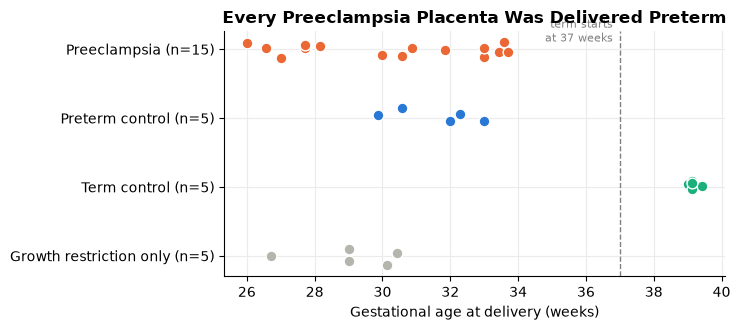

In [3]:
metadata["q6_group"] = np.select(
    [metadata["pe_status"] == "PE", metadata["control_type"] == "preterm_birth", metadata["control_type"] == "term_birth"],
    ["PE", "preterm_control", "term_control"], default="FGR_only")
GROUP_ORDER = ["PE", "preterm_control", "term_control", "FGR_only"]

display(metadata.groupby("q6_group")["ga_delivery_weeks"].agg(n="size", earliest="min", average="mean", latest="max")
        .reindex(GROUP_ORDER).round(1))

# Figure 1: when was each placenta delivered?
fig, ax = plt.subplots(figsize=(7.5, 3.4))
jitter = rng.uniform(-0.15, 0.15, len(metadata))
for i, g in enumerate(GROUP_ORDER):
    sel = (metadata["q6_group"] == g).values
    ax.scatter(metadata.loc[sel, "ga_delivery_weeks"], np.full(sel.sum(), i) + jitter[sel], s=60,
               color=COLORS[g], edgecolor="white", zorder=3)
ax.axvline(37, color="gray", ls="--", lw=1)
ax.text(36.8, -0.45, "term starts\nat 37 weeks", fontsize=8, color="gray", ha="right", va="top")
ax.set_yticks(range(4))
ax.set_yticklabels([f"{LABELS[g]} (n={(metadata['q6_group'] == g).sum()})" for g in GROUP_ORDER])
ax.invert_yaxis()
ax.set_xlabel("Gestational age at delivery (weeks)")
ax.set_title("Every Preeclampsia Placenta Was Delivered Preterm")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig1_delivery_timing.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Preeclampsia placentas were delivered between 26 and 34 weeks (average 30.2). Preterm controls fall in the same window (average 31.5), while term controls sit about 9 weeks later (average 39.2). In a typical study with only term controls, disease and delivery timing would be impossible to separate. The preterm controls are what make our question answerable.

One flagged value matters here: S26's delivery age was published as "38.7" (38 weeks + 7 days). We keep the released value of 39.0 weeks. It is a term control either way.

## 3. Explore the Samples

PCA squeezes each sample's ~16,000 gene measurements into two numbers so we can plot them. Samples close together have similar overall gene activity. We first keep genes with at least 10 reads in at least 5 samples, since almost-silent genes only add noise. We use this same gene list for every test below.

We color the plot two ways: by group, then by delivery week. If timing drove the biggest differences, the delivery-week coloring would show a smooth gradient along the first axis (PC1).

Genes kept: 15,835 of 26,485


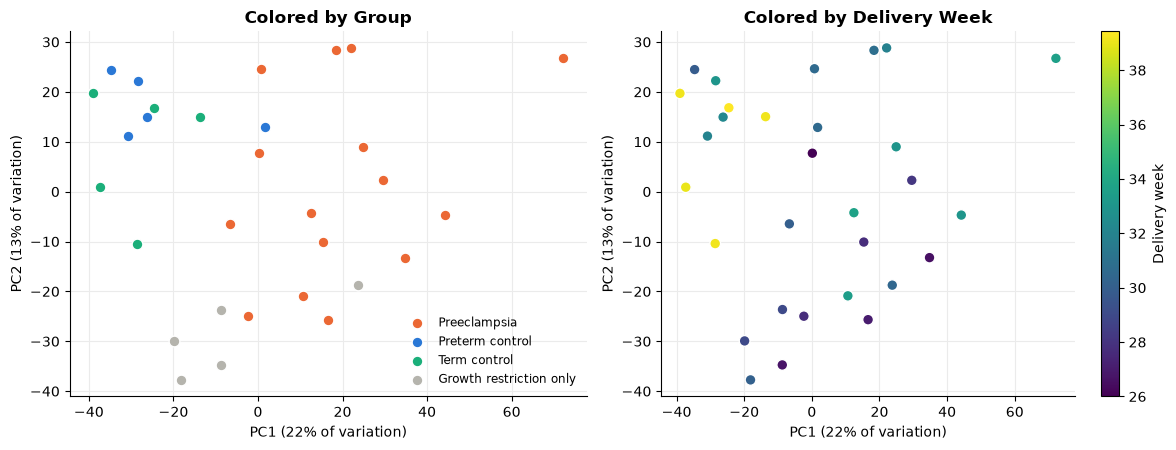

Share of PC1 explained by preeclampsia status: 54%   by delivery week: 12%
Average PC1 position: {'PE': 20.0, 'preterm_control': -24.0, 'term_control': -29.0, 'FGR_only': -6.0}


In [4]:
counts_f = counts.loc[(counts >= 10).sum(axis=1) >= 5]
print(f"Genes kept: {len(counts_f):,} of {len(counts):,}")
log_cpm = np.log2(counts_f.div(counts_f.sum(axis=0), axis=1) * 1e6 + 1)   # depth-adjusted, log scale
pca = PCA(n_components=2)
pcs = pd.DataFrame(pca.fit_transform(log_cpm.T), index=counts_f.columns, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for g in GROUP_ORDER:
    sel = metadata["q6_group"] == g
    axes[0].scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], s=60, color=COLORS[g], edgecolor="white", label=LABELS[g])
axes[0].legend(fontsize=8.5)
axes[0].set_title("Colored by Group")
pts = axes[1].scatter(pcs["PC1"], pcs["PC2"], c=metadata["ga_delivery_weeks"], cmap="viridis", s=60, edgecolor="white")
fig.colorbar(pts, ax=axes[1], label="Delivery week")
axes[1].set_title("Colored by Delivery Week")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig2_pca.png", dpi=300, bbox_inches="tight")
plt.show()

# How much of PC1 lines up with preeclampsia status vs delivery week? (squared correlation, 0 to 1)
r2_pe = np.corrcoef(pcs["PC1"], metadata["pe_status"] == "PE")[0, 1] ** 2
r2_ga = np.corrcoef(pcs["PC1"], metadata["ga_delivery_weeks"])[0, 1] ** 2
print(f"Share of PC1 explained by preeclampsia status: {r2_pe:.0%}   by delivery week: {r2_ga:.0%}")
print("Average PC1 position:", pcs["PC1"].groupby(metadata["q6_group"]).mean().reindex(GROUP_ORDER).round(0).to_dict())

**What this shows.** PC1 separates preeclampsia samples from both control groups in this dataset. Its association with PE is stronger than with delivery week, but PCA does not establish cause or rule out residual timing effects.

One preeclampsia sample (S01) sits far to the right. It lies in the same direction as the other cases, so it looks like an extreme case rather than a broken sample. Its read count (6.8 million) is below the median (11.7 million) but not the lowest in the dataset. Following the workflow guidance, we keep all 30 samples.

## 4. Choose a Comparison

**Our main comparison: preeclampsia (15) vs spontaneous preterm controls (5).** Their delivery weeks overlap but are not individually matched. This reduces the timing gap relative to term controls; it does not eliminate timing or other confounding.

We did not simply add delivery week as a covariate across all controls. The term controls all sit at 39 weeks, far outside the 26 to 34 week range of the cases. The model would have to guess how genes behave across that gap, with no cases there to check it.

The other comparisons we need (PE vs term controls, and preterm vs term controls) come in Section 9. We set all of them before looking at any results.

In [5]:
# Our decisions
GROUP_COLUMN = "q6_group"
CASE = "PE"
CONTROL = "preterm_control"
COVARIATES = []

def build_comparison(counts, metadata):
    used = [GROUP_COLUMN] + list(COVARIATES)
    meta = metadata[metadata[GROUP_COLUMN].isin([CASE, CONTROL])][used].copy()
    n_before = len(meta)
    meta = meta.dropna()
    if len(meta) < n_before:
        print(f"Note: {n_before - len(meta)} sample(s) dropped for missing values in {used}. Report this.")
    print(meta[GROUP_COLUMN].value_counts().to_string())
    return counts[meta.index], meta

comp_counts, comp_meta = build_comparison(counts_f, metadata)

q6_group
PE                 15
preterm_control     5


## 5. Run the Test

PyDESeq2 adjusts for sequencing depth, then asks for every gene: is the difference between the two groups bigger than the normal sample-to-sample variation? We wrap it in two small functions because later sections reuse it with identical settings.

In [6]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

INFERENCE = DefaultInference(n_cpus=os.cpu_count())

def fit_deseq(cnts, meta, design):
    dds = DeseqDataSet(counts=cnts.T.astype(int), metadata=meta, design=design, quiet=True, inference=INFERENCE)
    dds.deseq2()
    return dds

def test_contrast(dds, contrast):
    st = DeseqStats(dds, contrast=contrast, quiet=True, inference=INFERENCE)
    st.summary()
    return st.results_df.sort_values("padj")

design = "~" + " + ".join(list(COVARIATES) + [GROUP_COLUMN])
print("Design:", design)
results = test_contrast(fit_deseq(comp_counts, comp_meta, design), [GROUP_COLUMN, CASE, CONTROL])
results.to_csv(RESULTS_DIR / "de_results.csv")
print(f"Tested {len(results):,} genes. Saved to results/de_results.csv")
display(results.head(10))

Design: ~q6_group


Tested 15,835 genes. Saved to results/de_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
LEPROTL1,741.163767,1.000805,0.088343,11.328643,9.465982e-30,1.440344e-25
NTRK2,256.383815,3.860358,0.454034,8.502361,1.857728e-17,1.413359e-13
AFF3,260.879652,-1.653637,0.198556,-8.328325,8.199389e-17,4.158730e-13
COASY,820.215985,-0.994770,0.122086,-8.148096,3.697001e-16,1.406339e-12
AMD1,3677.103819,1.028512,0.134195,7.664304,1.798030e-14,5.471764e-11
ENG,7529.862816,2.090184,0.286009,7.308098,2.709494e-13,6.871277e-10
FLT1,126519.988711,2.999385,0.415550,7.217876,5.280568e-13,1.147845e-09
CP,162.539974,4.194032,0.582533,7.199644,6.037002e-13,1.148238e-09
HTRA4,9870.028873,2.970925,0.418948,7.091397,1.327651e-12,2.244616e-09


## 6. Read the Results

**Our cutoffs: adjusted p-value below 0.05 and at least a 2-fold change** (`|log2FoldChange| >= 1`).

- `padj < 0.05` is the usual standard. It means we expect about 5% of the genes we call to be false alarms.
- The 2-fold floor keeps effects large enough to matter biologically. With only 5 controls, small changes are the least trustworthy anyway.

The table under the plot shows how the count shifts with stricter or looser cutoffs.

472 genes pass (283 higher in preeclampsia, 189 lower).


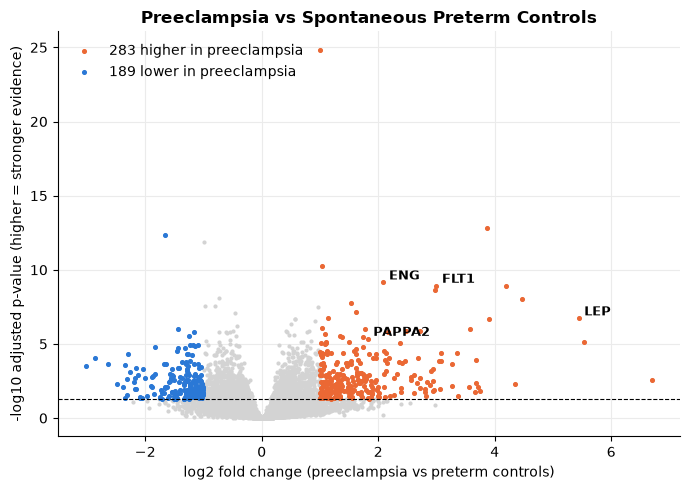

,at least 1.5-fold,at least 2.0-fold,at least 4.0-fold
padj < 0.01,613,293,67
padj < 0.05,1083,472,90
padj < 0.1,1377,564,96


In [7]:
PADJ_CUTOFF = 0.05
LFC_CUTOFF = 1.0

def passing_genes(res, padj=PADJ_CUTOFF, lfc=LFC_CUTOFF):
    return res[(res["padj"] < padj) & (res["log2FoldChange"].abs() >= lfc)]

hits = passing_genes(results)
hits.to_csv(RESULTS_DIR / "passing_genes.csv")
up, down = hits[hits["log2FoldChange"] > 0], hits[hits["log2FoldChange"] < 0]
print(f"{len(hits)} genes pass ({len(up)} higher in preeclampsia, {len(down)} lower).")

fig, ax = plt.subplots(figsize=(7, 5))
nlp = lambda r: -np.log10(r["padj"].clip(lower=1e-300))
ax.scatter(results["log2FoldChange"], nlp(results), s=4, color="lightgray", rasterized=True)
ax.scatter(up["log2FoldChange"], nlp(up), s=7, color=COLORS["PE"], label=f"{len(up)} higher in preeclampsia")
ax.scatter(down["log2FoldChange"], nlp(down), s=7, color=COLORS["preterm_control"], label=f"{len(down)} lower in preeclampsia")
ax.axhline(-np.log10(PADJ_CUTOFF), ls="--", lw=0.8, color="black")
for g in ["FLT1", "LEP", "ENG", "PAPPA2"]:
    ax.annotate(g, (results.loc[g, "log2FoldChange"], nlp(results.loc[[g]]).iloc[0]), fontsize=9, fontweight="bold",
                xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("log2 fold change (preeclampsia vs preterm controls)")
ax.set_ylabel("-log10 adjusted p-value (higher = stronger evidence)")
ax.set_title("Preeclampsia vs Spontaneous Preterm Controls")
ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "volcano.png", dpi=300, bbox_inches="tight")
plt.show()

display(pd.DataFrame({f"at least {2**l:.1f}-fold": {f"padj < {p}": len(passing_genes(results, p, l)) for p in (0.01, 0.05, 0.1)}
                      for l in (0.58, 1, 2)}))

**What this shows.** Against controls delivered in the same weeks, 472 genes differ at least 2-fold in this two-group model. (Section 9 fits one model to all three groups, which estimates noise from 25 placentas instead of 20, and finds 532 for the same comparison.) Most of them (283) are *higher* in preeclampsia. Several of the best-known preeclampsia genes are among the strongest hits:

- **FLT1** makes sFlt-1, a protein that blocks blood-vessel growth. Its blood level is part of a clinical test for preeclampsia.
- **ENG** (endoglin) makes another vessel-blocking protein.
- **LEP** (leptin) and **PAPPA2** are hormones known to be raised in preeclamptic placentas.

The gene count moves smoothly as the cutoffs change, so our story does not hinge on one particular threshold.

## 7. Connect Genes to Cell Types

Bulk tissue mixes many cell types. A marker is a gene used mostly by one cell type, so if several markers of one type move together, the tissue may simply contain more or less of that cell type. Here we check which of our passing genes are markers.

In [8]:
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
overlap = markers.merge(hits[["log2FoldChange", "padj"]], left_on="gene_symbol", right_index=True)
display(overlap.sort_values(["cell_class", "log2FoldChange"]) if not overlap.empty else "No passing genes are markers.")

,cell_class,compartment,gene_symbol,log2FoldChange,padj
13,decidual_nk_cell,maternal,KIT,1.778870,9.372973e-07
4,syncytiotrophoblast,fetal,CGA,1.168622,1.358346e-02


Next we looked up seven genes in the [Zeisel/Admati gene browser](https://storage.googleapis.com/www_zeisellab/PE_web/pe_web_test_v1.html), a single-cell map of placentas from a different preeclampsia study. We picked genes that tell our story, not just the top of the list:

- **FLT1, ENG, PAPPA2, LEP:** well measured, and higher in preeclampsia against *both* control groups.
- **HLA-G:** looks higher in preeclampsia only when compared with term controls (Section 11).

The browser does not explain its significance stars or which markers show preeclampsia and which show controls, so we do not use it for direction or significance. We record only which cell types express each gene and how specific the expression is. Browser images are supporting context from other patients, not proof, and cannot distinguish a change inside cells from a change in cell mix.


In [9]:
browser_lookups = pd.read_csv(Path("inputs/track01_browser_lookups.csv"))
required_columns = {"gene", "cell_types_expressing", "specificity", "differs_PE_vs_control", "notes"}
missing_columns = required_columns - set(browser_lookups.columns)
if missing_columns:
    raise ValueError(f"Browser lookup file is missing required columns: {sorted(missing_columns)}")
if len(browser_lookups) < 3:
    raise ValueError(f"Browser lookup file must contain at least three rows; found {len(browser_lookups)}")
blank_genes = browser_lookups["gene"].isna() | browser_lookups["gene"].astype(str).str.strip().eq("")
if blank_genes.any():
    raise ValueError("Browser lookup file contains blank gene symbols")
if browser_lookups["gene"].duplicated().any():
    raise ValueError("Browser lookup file contains duplicate gene symbols")

browser_lookups.to_csv(RESULTS_DIR / "browser_lookups.csv", index=False)
display(browser_lookups)


,gene,cell_types_expressing,specificity,differs_PE_vs_control,notes
0,LEP,SCT-PSG and SCT (syncytiotrophoblast),one type (syncytiotrophoblast subtypes),Not interpreted: the browser has no legend for...,"Most cell-type-specific of our genes, consiste..."
1,FLT1,"Extravillous trophoblast (highest), SCT-PSG an...",a few types (trophoblast-dominant),Not interpreted: the browser has no legend for...,Gene behind the clinical sFlt-1 test. Per cell...
2,HTRA4,"SCT, SCT-PSG, EVT2, EVT1",trophoblast only,Not interpreted: the browser has no legend for...,Trophoblast-restricted protease
3,PAPPA2,"Extravillous trophoblast and SCT-PSG, some SCT",trophoblast only,Not interpreted: the browser has no legend for...,Trophoblast-restricted; not assigned to a sing...
4,ENG,"Broad: endothelial cells, SCT, SCT-PSG, EVT an...",broad,Not interpreted: the browser has no legend for...,Too widespread to pin to one cell type from ex...
5,HSD17B1,SCT (highest) and villous cytotrophoblast,a few types (villous trophoblast),Not interpreted: the browser has no legend for...,Estrogen-synthesis enzyme; lower in PE in our ...
6,HLA-G,Extravillous trophoblast only,one type,Not interpreted: the browser has no legend for...,Classic extravillous trophoblast marker; in ou...


## 8. Optional: Single-Cell Extension

Not used in this walkthrough. The main analysis notebook ([`track01_analysis.ipynb`](track01_analysis.ipynb), Sections 9 and 10) uses the pseudobulk files to ask whether the preeclampsia genes are concentrated in particular cell types and in which cell type they change.

---
# Answering Question 6

## 9. Same Disease, Different Controls

If delivery timing were behind the preeclampsia signal, we would expect:

1. **PE vs term controls** (about 9 weeks apart) to show many more differences than **PE vs preterm controls** (same weeks). Both comparisons use 15 cases and 5 controls, so the comparison is fair.
2. **Preterm vs term controls** (no disease, 8 weeks apart) to show many differences of their own.

We fit one model with all three groups, so the three comparisons share the same estimates of noise. We also run the "naive" comparison many studies would start with: PE vs all 10 controls pooled.

In [10]:
cmp_meta = metadata.loc[metadata["q6_group"] != "FGR_only", ["q6_group", "fgr_status", "fetal_sex"]].copy()
cmp_meta["pe_vs_control"] = np.where(cmp_meta["q6_group"] == "PE", "PE", "control")
cmp_counts = counts_f[cmp_meta.index]

dds3 = fit_deseq(cmp_counts, cmp_meta, "~q6_group")
res = {
    "PE vs all controls (naive)": test_contrast(fit_deseq(cmp_counts, cmp_meta, "~pe_vs_control"), ["pe_vs_control", "PE", "control"]),
    "PE vs term controls": test_contrast(dds3, ["q6_group", "PE", "term_control"]),
    "PE vs preterm controls": test_contrast(dds3, ["q6_group", "PE", "preterm_control"]),
    "Preterm vs term controls": test_contrast(dds3, ["q6_group", "preterm_control", "term_control"]),
}
for name, r in res.items():
    r.to_csv(RESULTS_DIR / f"de_{name.split(' (')[0].replace(' ', '_')}.csv")

de_counts = pd.DataFrame({
    "samples": ["15 vs 10", "15 vs 5", "15 vs 5", "5 vs 5"],
    "genes passing": [len(passing_genes(r)) for r in res.values()],
}, index=res.keys())
de_counts.to_csv(RESULTS_DIR / "de_counts_by_comparison.csv")
display(de_counts)

,samples,genes passing
PE vs all controls (naive),15 vs 10,582
PE vs term controls,15 vs 5,532
PE vs preterm controls,15 vs 5,532
Preterm vs term controls,5 vs 5,11


In [11]:
# Equal counts are not the same genes: how much do the two PE comparisons agree?
a = set(passing_genes(res["PE vs term controls"]).index)
b = set(passing_genes(res["PE vs preterm controls"]).index)
union = sorted(a | b)
lfc_t = res["PE vs term controls"].loc[union, "log2FoldChange"]
lfc_p = res["PE vs preterm controls"].loc[union, "log2FoldChange"]
overlap_stats = {"shared": len(a & b), "only_vs_term": len(a - b), "only_vs_preterm": len(b - a),
                 "lfc_correlation": round(lfc_t.corr(lfc_p), 2), "same_direction": round((np.sign(lfc_t) == np.sign(lfc_p)).mean(), 2)}
pd.Series(overlap_stats).to_csv(RESULTS_DIR / "pe_comparisons_overlap.csv")
print(f"{len(a & b)} shared | {len(a - b)} only vs term | {len(b - a)} only vs preterm")
print(f"Across all {len(union)} genes passing either comparison: fold-change correlation {overlap_stats['lfc_correlation']}, "
      f"same direction {overlap_stats['same_direction']:.0%}")

240 shared | 292 only vs term | 292 only vs preterm
Across all 824 genes passing either comparison: fold-change correlation 0.76, same direction 95%


**What this shows.** At this threshold, the PE comparisons yield 532 passing genes with either term or same-time preterm controls. Equal counts do not mean the same genes: only 240 genes pass both comparisons, while 292 pass only against term controls and 292 only against preterm controls. Across all 824 genes that pass either one, the fold changes correlate at 0.76 and 95% point the same way. So the direction of the preeclampsia signal holds when the control group changes, but the exact gene list shifts. The two control groups, delivered 8 weeks apart, differ in **11** genes; the naive pooled comparison finds 582.

The 5-vs-5 control comparison is small and may miss real effects. Section 10 explores same-size comparisons, but cannot rule out limited power or confounding.

## 10. Is That Just Because 5 vs 5 Is a Small Test?

With only 5 samples per group, a test can miss real differences. To check, we ran two other comparisons of exactly the same size, 20 times each:

- **5 random preeclampsia cases vs the 5 preterm controls.** This shows how many genes a real disease difference produces at this sample size.
- **The 10 controls split into two random groups of 5.** Most splits mix preterm and term controls, so this is a rough noise baseline that still carries some timing signal.

These exploratory draws provide context for the number of passing genes, but do not quantify power or isolate the effect of timing.

5 PE vs 5 preterm controls: [232, 308, 312, 337, 421, 451, 456, 494, 502, 508, 567, 575, 602, 611, 620, 631, 634, 714, 739, 763]
Random split of controls:   [0, 0, 1, 1, 2, 2, 3, 3, 5, 5, 5, 5, 6, 6, 6, 7, 9, 10, 12, 17]
Preterm vs term controls:   11


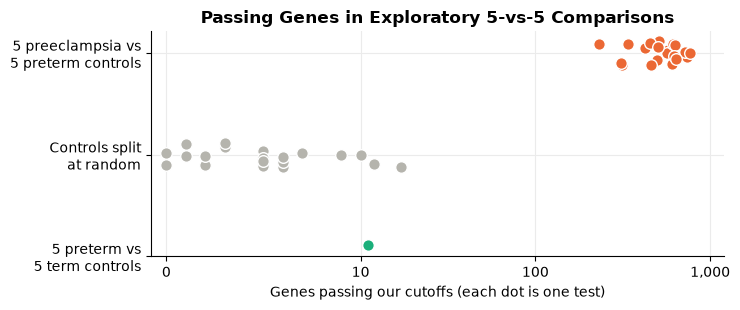

In [12]:
N_DRAWS = 20
pe_ids = cmp_meta.index[cmp_meta["q6_group"] == "PE"].tolist()
pre_ids = cmp_meta.index[cmp_meta["q6_group"] == "preterm_control"].tolist()
term_ids = cmp_meta.index[cmp_meta["q6_group"] == "term_control"].tolist()

def n_genes_5v5(a_ids, b_ids):
    m = pd.DataFrame({"grp": ["A"] * 5 + ["B"] * 5}, index=list(a_ids) + list(b_ids))
    return len(passing_genes(test_contrast(fit_deseq(counts_f[m.index], m, "~grp"), ["grp", "A", "B"])))

disease_draws, noise_draws = [], []
for _ in range(N_DRAWS):
    disease_draws.append(n_genes_5v5(rng.choice(pe_ids, 5, replace=False), pre_ids))
    split = list(rng.permutation(pre_ids + term_ids))
    while set(split[:5]) in (set(pre_ids), set(term_ids)):      # skip the real split
        split = list(rng.permutation(pre_ids + term_ids))
    noise_draws.append(n_genes_5v5(split[:5], split[5:]))
timing_actual = len(passing_genes(res["Preterm vs term controls"]))
pd.DataFrame({"disease_5v5": disease_draws, "noise_5v5": noise_draws}).to_csv(RESULTS_DIR / "power_check.csv", index=False)
print("5 PE vs 5 preterm controls:", sorted(disease_draws))
print("Random split of controls:  ", sorted(noise_draws))
print("Preterm vs term controls:  ", timing_actual)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
rows = [("5 preeclampsia vs\n5 preterm controls", disease_draws, COLORS["PE"]),
        ("Controls split\nat random", noise_draws, "#b5b4ad"),
        ("5 preterm vs\n5 term controls", [timing_actual], COLORS["term_control"])]
for i, (lab, vals, c) in enumerate(rows):
    ax.scatter(vals, i + rng.uniform(-0.12, 0.12, len(vals)), s=70, color=c, edgecolor="white", zorder=3)
ax.set_yticks(range(3)); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(-0.8, 1200)
ax.set_xticks([0, 10, 100, 1000]); ax.set_xticklabels(["0", "10", "100", "1,000"])
ax.set_xlabel("Genes passing our cutoffs (each dot is one test)")
ax.set_title("Passing Genes in Exploratory 5-vs-5 Comparisons")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig3_power_check.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Across 20 draws each, five preeclampsia cases against five preterm controls produce 232 to 763 genes, so a 5-vs-5 test *can* detect a real biological difference. Random splits of the controls produce 0 to 17 genes. The real preterm-vs-term comparison gives 11, inside that noise range and far below the disease effect at the same sample size.

These few draws do not exclude low power, delivery-related confounding, or effects missed by the chosen threshold.

## 11. Putting a Number on It

Take every gene that passes for **PE vs term controls**, the comparison most exposed to timing. On the log scale, its difference splits exactly into two parts:

> (PE vs term) = (PE vs preterm) **+** (preterm vs term)
>
> total contrast = **PE-vs-preterm contrast** + **preterm-vs-term contrast**

This is an algebraic decomposition of model contrasts, not a causal separation of disease from timing. The output labels below are descriptive, not proof of cause:

- **Passes against preterm controls:** still significant against preterm controls, in the same direction.
- **Control contrast >= 50%:** no longer significant against preterm controls, and the preterm-vs-term contrast is at least half of the original difference.
- **Unclear:** neither; the data are too noisy to say.

532 genes differ between preeclampsia and term controls. Of these:
   53%  Passes against preterm controls
   18%  Unclear
   28%  Control contrast >= 50%

Median preterm-vs-term component: 30% of the PE-vs-term contrast (not a causal estimate).

Best-measured genes explained by timing:


,total,disease,timing,baseMean
gene,,,,
FN1,2.17,0.74,1.43,126833.35
PSG2,1.00,0.31,0.70,31776.41
TIMP3,1.39,0.39,1.00,17349.15
PRG2,3.00,0.41,2.59,16295.87
SERPINE1,1.36,0.60,0.75,9081.41
AOC1,1.90,0.74,1.16,8627.70
ISM2,1.17,0.13,1.04,4303.37
MUC15,-1.16,-0.49,-0.67,2163.27


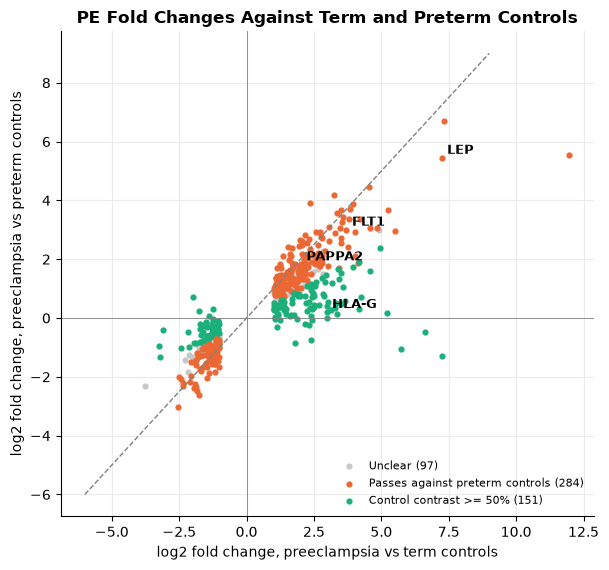

In [13]:
lfc = pd.DataFrame({k: res[k]["log2FoldChange"] for k in ["PE vs term controls", "PE vs preterm controls", "Preterm vs term controls"]})
lfc.columns = ["total", "disease", "timing"]
padj_disease = res["PE vs preterm controls"]["padj"]

term_hits = passing_genes(res["PE vs term controls"]).index
holds = (padj_disease < PADJ_CUTOFF) & (np.sign(lfc["disease"]) == np.sign(lfc["total"]))
timing_share = lfc["timing"] / lfc["total"]
category = pd.Series("Unclear", index=term_hits)
category[holds[term_hits]] = "Passes against preterm controls"
category[(~holds & (timing_share >= 0.5))[term_hits]] = "Control contrast >= 50%"
share = category.value_counts(normalize=True)

print(f"{len(term_hits)} genes differ between preeclampsia and term controls. Of these:")
for c in ["Passes against preterm controls", "Unclear", "Control contrast >= 50%"]:
    print(f"  {share.get(c, 0):4.0%}  {c}")
print(f"\nMedian preterm-vs-term component: {timing_share[term_hits].median():.0%} of the PE-vs-term contrast (not a causal estimate).")
category.rename("category").to_frame().join(lfc).to_csv(RESULTS_DIR / "pe_vs_term_genes_classified.csv")
print("\nBest-measured genes explained by timing:")
display(lfc.loc[category.index[category == "Control contrast >= 50%"]]
        .join(res["PE vs term controls"]["baseMean"]).sort_values("baseMean", ascending=False).head(8).round(2))

# Figure: each gene's difference against term controls (x) and against same-time controls (y)
cat_colors = {"Passes against preterm controls": COLORS["PE"], "Unclear": "#c8c8c8", "Control contrast >= 50%": COLORS["term_control"]}
fig, ax = plt.subplots(figsize=(6.2, 5.8))
for c in ["Unclear", "Passes against preterm controls", "Control contrast >= 50%"]:
    g = category.index[category == c]
    ax.scatter(lfc.loc[g, "total"], lfc.loc[g, "disease"], s=12, color=cat_colors[c], label=f"{c} ({len(g)})")
ax.plot([-6, 9], [-6, 9], color="gray", ls="--", lw=1)
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
for g in ["FLT1", "LEP", "PAPPA2", "HLA-G"]:
    ax.annotate(g, (lfc.loc[g, "total"], lfc.loc[g, "disease"]), fontsize=9, fontweight="bold", xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("log2 fold change, preeclampsia vs term controls")
ax.set_ylabel("log2 fold change, preeclampsia vs preterm controls")
ax.set_title("PE Fold Changes Against Term and Preterm Controls")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig4_term_vs_preterm_fold_changes.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Of the 532 genes that differ between preeclampsia and term controls:

- **About half (53%) hold up** against controls delivered in the same weeks. These include FLT1, LEP and PAPPA2, which sit close to the dashed line in the plot, meaning they show the same size of difference against either control group.
- **About a quarter (28%) meet the notebook's timing-associated classification.** These are green points that fall toward zero when preterm controls are used; this does not establish that timing caused the difference.
- **The rest (18%) are unclear.**

The median preterm-vs-term component is about **30%** of the PE-vs-term contrast among these selected genes. This ratio is model-dependent, not a causal fraction.

The control groups may differ in delivery circumstances and tissue composition as well as gestational age, so the component cannot be interpreted as timing alone.

## 12. Seeing It Sample by Sample

Two genes show the two patterns. Each dot is one placenta, plotted by delivery week.

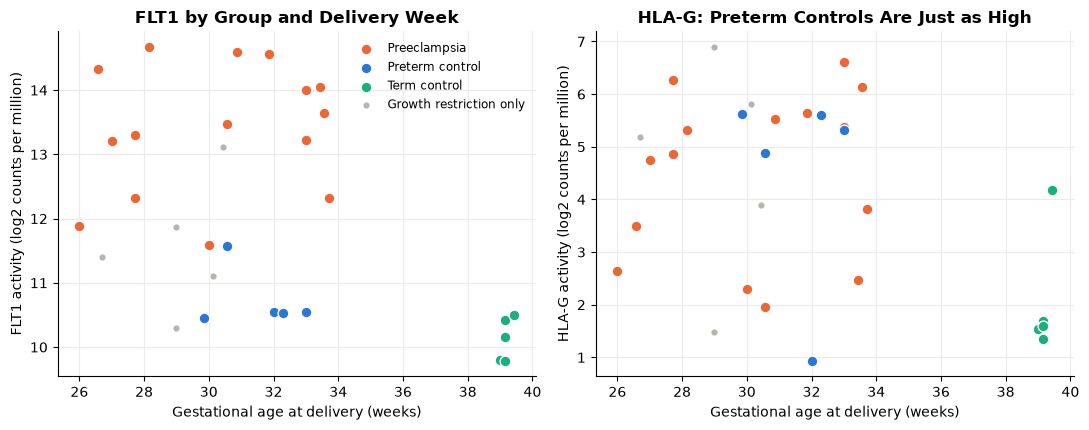

In [14]:
def gene_vs_week(ax, gene, legend=False):
    for g in GROUP_ORDER:
        sel = metadata["q6_group"] == g
        ax.scatter(metadata.loc[sel, "ga_delivery_weeks"], log_cpm.loc[gene, sel], s=60 if g != "FGR_only" else 30,
                   color=COLORS[g], edgecolor="white", label=LABELS[g], zorder=3 if g != "FGR_only" else 2)
    ax.set_xlabel("Gestational age at delivery (weeks)")
    ax.set_ylabel(f"{gene} activity (log2 counts per million)")
    if legend:
        ax.legend(fontsize=8.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
gene_vs_week(axes[0], "FLT1", legend=True)
axes[0].set_title("FLT1 by Group and Delivery Week")
gene_vs_week(axes[1], "HLA-G")
axes[1].set_title("HLA-G: Preterm Controls Are Just as High")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig5_genes_by_delivery_week.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** FLT1 is higher in many PE samples. HLA-G varies with control choice; this plot does not establish whether timing, tissue mix, or other factors caused that pattern. Browser annotations are qualitative.

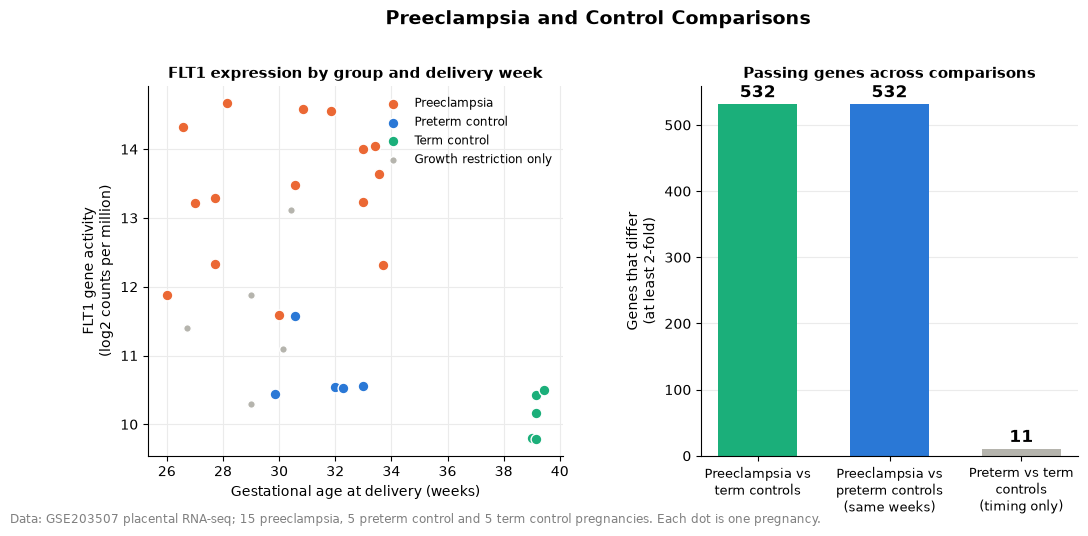

In [15]:
# Summary figure for this walkthrough (the team headline is figures/headline.png from the main analysis)
n_term, n_pre, n_time = (len(passing_genes(res[k])) for k in ["PE vs term controls", "PE vs preterm controls", "Preterm vs term controls"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.35})
gene_vs_week(axes[0], "FLT1", legend=True)
axes[0].set_ylabel("FLT1 gene activity\n(log2 counts per million)")
axes[0].set_title("FLT1 expression by group and delivery week", fontsize=11)
bars = [("Preeclampsia vs\nterm controls", n_term, COLORS["term_control"]),
        ("Preeclampsia vs\npreterm controls\n(same weeks)", n_pre, COLORS["preterm_control"]),
        ("Preterm vs term\ncontrols\n(timing only)", n_time, "#b5b4ad")]
for i, (lab, v, c) in enumerate(bars):
    axes[1].bar(i, v, color=c, width=0.6)
    axes[1].text(i, v + 10, str(v), ha="center", fontsize=12, fontweight="bold")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels([b[0] for b in bars], fontsize=9.5)
axes[1].set_ylabel("Genes that differ\n(at least 2-fold)")
axes[1].grid(axis="x", visible=False)
axes[1].set_title("Passing genes across comparisons", fontsize=11)
fig.suptitle("Preeclampsia and Control Comparisons", fontsize=14, fontweight="bold", y=1.04)
fig.text(0.01, -0.03, "Data: GSE203507 placental RNA-seq; 15 preeclampsia, 5 preterm control and 5 term control pregnancies. "
         "Each dot is one pregnancy.", fontsize=8.5, color="gray")
plt.savefig(RESULTS_DIR / "workflow_summary.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Robustness Checks

We reran the main comparison (PE vs preterm controls) four ways. The first three target something other than timing that differs between the groups; the fourth drops the two most unusual preeclampsia samples:

- **Growth restriction:** 7 of the 15 cases also have growth restriction (FGR), and no preterm control does. We add `fgr_status` as a covariate.
- **Fetal sex:** placental gene activity differs by the baby's sex. We add `fetal_sex` as a covariate.
- **Remaining timing gap:** cases were delivered about 1.3 weeks earlier than preterm controls on average. We add delivery week as a covariate.
- **Unusual samples:** S01 sits far from all other samples on PC1 (Section 3), and S12 is a preeclampsia case whose recorded blood pressure never reached 140/90. We drop both.

For each, we ask what share of our main genes still pass in the same direction.

In [16]:
main = res["PE vs preterm controls"]
main_hits = passing_genes(main).index
pt = metadata.loc[pe_ids + pre_ids, ["q6_group", "fgr_status", "fetal_sex", "ga_delivery_weeks"]]
rows = {}
for name, design in [("+ growth restriction", "~fgr_status + q6_group"), ("+ fetal sex", "~fetal_sex + q6_group"),
                     ("+ delivery week", "~ga_delivery_weeks + q6_group"), ("drop S01 and S12", "~q6_group")]:
    use = pt.index.drop(["S01_VT", "S12_VT"]) if name.startswith("drop") else pt.index
    r = test_contrast(fit_deseq(counts_f[use], pt.loc[use], design), ["q6_group", "PE", "preterm_control"])
    same = (r.loc[main_hits, "padj"] < PADJ_CUTOFF) & (np.sign(r.loc[main_hits, "log2FoldChange"]) == np.sign(main.loc[main_hits, "log2FoldChange"]))
    rows[name] = {"genes passing": len(passing_genes(r)), "main genes still significant, same direction": f"{same.mean():.0%}",
                  "fold-change agreement (correlation)": round(r.loc[main_hits, "log2FoldChange"].corr(main.loc[main_hits, "log2FoldChange"]), 2)}
robust = pd.DataFrame(rows).T
robust.to_csv(RESULTS_DIR / "robustness_checks.csv")
print(f"Main comparison: {len(main_hits)} genes")
display(robust)

Main comparison: 532 genes


,genes passing,"main genes still significant, same direction",fold-change agreement (correlation)
+ growth restriction,293,52%,0.99
+ fetal sex,426,76%,1.0
+ delivery week,529,86%,0.99
drop S01 and S12,453,84%,1.0


**What this shows.** Fold-change estimates are highly correlated with the main analysis in these sensitivity checks. Correlation alone does not establish equal effect sizes or rule out confounding.

- Adjusting for the remaining 1.3-week average timing gap keeps 86% of the main genes significant.
- Adjusting for fetal sex keeps 76%.
- Dropping S01 and S12 keeps 84%, with fold changes matching almost exactly (correlation 1.0), so neither unusual sample drives the result.
- Adjusting for growth restriction keeps 52%. Growth restriction occurs only in the PE group in this core comparison, making the adjusted effect difficult to estimate precisely. The secondary analysis adds 5 FGR-only controls and uses a different model.

---
## Our Answer

**Preeclampsia and spontaneous-preterm controls differ in this dataset, but the contribution of delivery timing remains uncertain.**

- The PE-vs-term and PE-vs-preterm contrasts each yield 532 passing genes, but only 240 are shared. Their fold changes correlate at 0.76 and 95% point the same way: the direction holds when the control group changes, the exact gene list does not.
- Control placentas delivered 8 weeks apart differ in only 11 genes, inside the range random splits of the controls produce (0 to 17).
- About half of the selected differences against term controls also pass against preterm controls; an algebraic decomposition is not proof of causation.
- FLT1, ENG, LEP and PAPPA2 are higher in the tested contrasts; this does not establish their behavior at all delivery times.
- The secondary adjusted analysis reports a median 8% change in estimated effects after adding a term indicator. It uses a different model and does not measure a causal timing fraction (see `track01_analysis.ipynb`).

**Limitations.**

- Our preterm controls are spontaneous preterm births, which often involve inflammation. They are the best comparison available, since healthy pregnancies are not delivered early, but they are not a healthy 31-week placenta.
- There are only 5 controls of each type.
- Bulk tissue mixes many cell types, so we cannot tell whether genes change inside cells or because the cell mix changes.
- All cases are early onset, so the answer may differ for late-onset preeclampsia.
- All of this is association, not cause.

**Next steps.**

- Check FLT1, ENG, LEP and PAPPA2 against preterm controls in an independent cohort whose preterm deliveries were medically indicated rather than spontaneous.

Go to [Step 4: Submit](../4-submit.md).